# 10주차. 멀티에이전트 ① — 모델 라우팅 (CPU)

(윈도우, 건물)마다 예측기 풀에서 하나를 고르는 라우터를 만들고, **최고 단일 모델 · 규칙 라우터 · LLM 라우터 · 오라클**을 같은 하네스에서 비교한다.

**설계 (평가의 정직성)**
- 후보 6종의 윈도우별 예측은 1~8주차에 이미 저장돼 있다 → 라우터가 고른 예측을 **조회**해 2주차 하네스(`score_backtest`)로 채점한다. 모델을 다시 학습·추론하지 않는다(부족한 LightGBM local·TTM만 생성).
- **누수 방지**: 규칙과 LLM 프롬프트의 근거는 **앞 26창**에서만 만들고, 모든 비교는 **뒤 26창**에서만 한다. 최고 단일 모델도 앞 26창 성적으로 정한다. 상태 신호는 origin 이전 데이터로만 계산한다.
- 풀: Seasonal Naive · LightGBM(local) · LightGBM(global) · Chronos-2 · Chronos-2 + 공변량 · TTM(ctx 512). 딥러닝 4종·LoRA는 제외(성능이 낮고 체크포인트가 없어 실제 호출이 어려움).
- 상태 신호 5종: 이력 길이 · 결측률(최근 28일) · 공변량 유무(외기온 가용률) · 주기성 강도(자기상관) · 최근 잔차 수준(직전 1주 Naive 오차).

In [1]:
import sys, os, time, json, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.stats import wilcoxon, spearmanr

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from src import routing as rt, bench_models as bm

OUT = ROOT / "results/wk10"
(OUT / "preds").mkdir(parents=True, exist_ok=True)
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if f in {x.name for x in font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

H = rt.HORIZONS
data = bm.load_data()
print("데이터:", data.shape, "| 풀:", rt.POOL)
print("규칙 근거 창:", rt.FIT_W[[0, -1]], "| 평가 창:", rt.EVAL_W[[0, -1]])

데이터: (17544, 17) | 풀: ['Seasonal Naive', 'LightGBM (local)', 'LightGBM (global)', 'Chronos-2', 'Chronos-2 + 공변량', 'TTM (ctx=512)']
규칙 근거 창: [ 0 25] | 평가 창: [26 51]


## 과제 10-1. 예측기 인터페이스 통일

`Forecaster(name)(train_df, horizon) → DataFrame(horizon × 건물)`. 라우터는 어떤 예측기든 이 한 가지 방식으로 호출한다.
`cached`는 저장된 윈도우별 예측을 origin 시각으로 조회하고, `live`는 `bench_models`의 실제 모델을 호출한다(두 방식이 같은 값을 내는지 아래에서 점검).

In [2]:
t0 = time.time()
rt.make_missing_preds(data)  # 윈도우별 예측이 없는 LightGBM(local)·TTM(512) 생성 (있으면 건너뜀)
pools = {h: rt.Pool(data, h) for h in H}
print("풀 준비 %.0fs | 윈도우 %d개 × 건물 %d개" % (time.time() - t0, pools[24].W, len(data.columns)))

# 회귀 점검: 이 풀에서 하네스로 채점한 단일 모델 MASE 가 6주차 표와 같은가
prev = pd.read_csv(ROOT / "results/wk6/mase_summary.csv", index_col=0)
rows = {}
for h in H:
    for n in rt.POOL:
        rows.setdefault(n, {})[f"{h}h 이번"] = pools[h].score(np.full((pools[h].W, 17), n, dtype=object), range(pools[h].W))[0]
        rows[n][f"{h}h 6주차"] = prev.loc[n, f"MASE({h}h)"]
chk = pd.DataFrame(rows).T
chk["최대 차이"] = (chk[["24h 이번", "168h 이번"]].to_numpy() - chk[["24h 6주차", "168h 6주차"]].to_numpy()).__abs__().max(axis=1)
print(chk.round(4).to_string())
assert chk["최대 차이"].max() < 1e-3, "풀 점수가 6주차와 다름 — 예측 파일·정렬 점검"

풀 준비 1s | 윈도우 52개 × 건물 17개


                   24h 이번  24h 6주차  168h 이번  168h 6주차  최대 차이
Seasonal Naive     0.9673   0.9673   0.9767    0.9767    0.0
LightGBM (local)   0.5501   0.5501   0.9298    0.9298    0.0
LightGBM (global)  0.6211   0.6211   0.9955    0.9955    0.0
Chronos-2          0.3837   0.3837   0.8100    0.8100    0.0
Chronos-2 + 공변량    0.3545   0.3545   0.6969    0.6969    0.0
TTM (ctx=512)      0.7447   0.7447   1.0899    1.0899    0.0


In [3]:
# 통일 인터페이스 점검: cached 와 live 가 같은 예측을 내는가 (24h, 윈도우 30, CPU)
fc = {n: rt.Forecaster(n, "cached", pools=pools) for n in rt.POOL}
w = 30
t_origin = pools[24].origin_ts[w]
train = data.loc[:t_origin - pd.Timedelta(hours=1)]
LIVE_CHECK = ["Seasonal Naive", "LightGBM (local)", "LightGBM (global)", "TTM (ctx=512)"]  # Chronos-2 는 모델 다운로드가 커서 제외
rows = []
for n in rt.POOL:
    c = fc[n](train, 24)
    assert c.shape == (24, 17)
    r = {"모델": n, "cached 모양": c.shape, "지연(ms/계열, 6주차)": fc[n].latency}
    if n in LIVE_CHECK:
        lv = rt.Forecaster(n, "live", data=data)(train, 24)
        r["live-cached 최대 차이"] = float(np.nanmax(np.abs(lv.to_numpy() - c.to_numpy())))
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

C:\Users\dong\AppData\Local\Temp\wk9venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO:p-32068:t-12320:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2


INFO:p-32068:t-12320:get_model.py:get_model:Model path type is 2


INFO:p-32068:t-12320:get_model.py:get_model:Attempting model load from ibm-granite/granite-timeseries-ttm-r2, revision = 512-48-ft-r2.1.


INFO:p-32068:t-12320:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 512-48-ft-r2.1.


INFO:p-32068:t-12320:get_model.py:get_model:[TTM] context_length = 512, prediction_length = 48


               모델 cached 모양  지연(ms/계열, 6주차)  live-cached 최대 차이
   Seasonal Naive  (24, 17)         0.07190       0.000000e+00
 LightGBM (local)  (24, 17)        17.81010       2.273737e-13
LightGBM (global)  (24, 17)        25.28430       2.273737e-13
        Chronos-2  (24, 17)       154.66110                NaN
  Chronos-2 + 공변량  (24, 17)       294.08345                NaN
    TTM (ctx=512)  (24, 17)         4.40435       4.863281e-05


## 과제 10-2. 상태 수집 노드

(윈도우, 건물)마다 신호를 origin **이전** 데이터로만 계산한다.
- `hist_len` 이력 길이(관측 시간 수) · `miss_28d` 직전 28일 결측률 · `has_weather` 직전 28일 외기온 가용률 · `acf168`/`acf24` 직전 8주 자기상관 · `recent_naive_mase` 직전 1주의 Seasonal Naive 오차(MASE 단위) = "최근 잔차 수준"

In [4]:
state = rt.state_table(data, pools[24])
state.to_csv(OUT / "state_signals.csv", index=False, encoding="utf-8")
print(state[rt.SIGNALS].describe().round(3).to_string())
print()
print("이력 길이 범위(h): %d ~ %d | 공변량 가용률 최소 %.2f" % (state.hist_len.min(), state.hist_len.max(), state.has_weather.min()))

# 신호가 실제 승패와 얼마나 관련 있나 (판정 기준 ①): 칸별 '최고 단일 모델을 이기는 다른 모델의 이득' vs 신호의 Spearman 상관
cm = {h: pools[h].cell_mase() for h in H}
fitm = state["window"].isin(rt.FIT_W).to_numpy()
rows = []
for h in H:
    E = pd.DataFrame({n: cm[h][n].reshape(-1) for n in rt.POOL})  # 칸 순서 = (윈도우, 건물) = state 행 순서
    default = E[fitm].mean().idxmin()
    gap = E[default] - E.drop(columns=default).min(axis=1)  # 양수 = 누군가 default 를 이김
    for sig in rt.SIGNALS:
        if state[sig].nunique() > 1:
            rows.append({"horizon": h, "신호": sig, "Spearman(신호, 이득)": spearmanr(state[sig][fitm], gap[fitm]).statistic})
sig_corr = pd.DataFrame(rows).pivot(index="신호", columns="horizon", values="Spearman(신호, 이득)")
sig_corr.to_csv(OUT / "signal_vs_gain.csv", encoding="utf-8")
print()
print("앞 26창: 신호 vs '다른 모델이 최고 단일 모델을 이기는 정도' 상관")
print(sig_corr.round(3).to_string())

        hist_len  miss_28d  has_weather   acf168    acf24  recent_naive_mase
count    884.000   884.000      884.000  884.000  884.000            884.000
mean   13219.621     0.001        1.000    0.621    0.688              0.976
std     2520.494     0.007        0.002    0.280    0.153              1.000
min     8843.000     0.000        0.967   -0.245   -0.030              0.033
25%    11001.000     0.000        1.000    0.451    0.616              0.391
50%    13160.500     0.000        1.000    0.686    0.697              0.715
75%    15339.250     0.000        1.000    0.866    0.804              1.197
max    17520.000     0.107        1.000    0.973    0.966             10.029

이력 길이 범위(h): 8843 ~ 17520 | 공변량 가용률 최소 0.97

앞 26창: 신호 vs '다른 모델이 최고 단일 모델을 이기는 정도' 상관
horizon              24     168
신호                             
acf168            -0.008 -0.083
acf24             -0.037 -0.053
has_weather        0.010 -0.021
hist_len          -0.053 -0.022
miss_28d          -0.006  0

## 과제 10-3. 규칙 기반 라우터

1. **앞 26창** 성적으로 최고 단일 모델(기본값)을 정한다.
2. 교재의 5가지 규칙을 앞 26창에서 실측해 **각 규칙의 근거(또는 반증)** 를 표로 남긴다.
3. 데이터에서 규칙을 탐색한다 — 신호 임계값 → 대체 모델. 통과 조건: 지원 칸 ≥ 60, 개선율 ≥ 3%, 앞·뒤 절반 모두 ≥ 1% 개선(우연한 규칙 배제).
4. 평가는 뒤 26창.

In [5]:
fit_idx = np.flatnonzero(fitm)
S_fit = state.iloc[fit_idx].reset_index(drop=True)
E_fit = {h: pd.DataFrame({n: cm[h][n].reshape(-1)[fit_idx] for n in rt.POOL}) for h in H}
DEFAULT = {h: E_fit[h].mean().idxmin() for h in H}
ev_tbl = pd.DataFrame({f"{h}h": E_fit[h].mean() for h in H})
ev_tbl["지연(ms/계열)"] = pd.Series(rt.latency_ms())
print("앞 26창 모델별 평균 MASE (규칙·LLM 의 근거 표)")
print(ev_tbl.round(4).to_string())
print("최고 단일 모델(앞 26창 기준):", DEFAULT)
ev_tbl.to_csv(OUT / "fit_window_evidence.csv", encoding="utf-8")

# 교재 규칙 점검 (앞 26창)
med_recent = S_fit.groupby("building")["recent_naive_mase"].transform("median")
TEXTBOOK = [
    ("R1 이력 < 3개월 → TSFM zero-shot", S_fit.hist_len < 2160, "Chronos-2 + 공변량"),
    ("R2 이력 > 1년 + 공변량 → LightGBM (local)", (S_fit.hist_len > 8760) & (S_fit.has_weather >= 0.9), "LightGBM (local)"),
    ("R2' 이력 > 1년 + 공변량 → LightGBM (global)", (S_fit.hist_len > 8760) & (S_fit.has_weather >= 0.9), "LightGBM (global)"),
    ("R3 강한 주기성(acf168 > 0.8) + 안정 → Seasonal Naive", (S_fit.acf168 > 0.8) & (S_fit.recent_naive_mase <= med_recent), "Seasonal Naive"),
    ("R4 계열 수 많음 + 지연 엄격 → TTM", pd.Series(False, index=S_fit.index), "TTM (ctx=512)"),
    ("R5 최근 잔차 3배 급증 → 이상 분기(여기선 Naive 로 대체 평가)", S_fit.recent_naive_mase > 3 * med_recent, "Seasonal Naive"),
]
rows = []
for h in H:
    for name, mask, target in TEXTBOOK:
        rows.append({"horizon": h, "규칙": name, "대상": target, **rt.check_rule(S_fit, E_fit[h], mask.to_numpy(), target, DEFAULT[h])})
tb = pd.DataFrame(rows)
tb.to_csv(OUT / "textbook_rules_check.csv", index=False, encoding="utf-8")
print()
print(tb.round(3).to_string(index=False))

앞 26창 모델별 평균 MASE (규칙·LLM 의 근거 표)
                      24h    168h  지연(ms/계열)
Seasonal Naive     0.8371  0.9221     0.0719
LightGBM (local)   0.5260  0.9171    17.8101
LightGBM (global)  0.6228  0.9557    25.2843
Chronos-2          0.3721  0.7442   154.6611
Chronos-2 + 공변량    0.3404  0.6251   294.0834
TTM (ctx=512)      0.7165  1.0309     4.4044
최고 단일 모델(앞 26창 기준): {24: 'Chronos-2 + 공변량', 168: 'Chronos-2 + 공변량'}

 horizon                                            규칙                대상  발동 칸 수  default MASE  target MASE   개선율(%)
      24                  R1 이력 < 3개월 → TSFM zero-shot   Chronos-2 + 공변량       0           NaN          NaN      NaN
      24           R2 이력 > 1년 + 공변량 → LightGBM (local)  LightGBM (local)     442         0.340        0.526  -54.509
      24         R2' 이력 > 1년 + 공변량 → LightGBM (global) LightGBM (global)     442         0.340        0.623  -82.946
      24 R3 강한 주기성(acf168 > 0.8) + 안정 → Seasonal Naive    Seasonal Naive      98         0.279        0.506  -81.1

In [6]:
RULES = {h: rt.fit_rules(S_fit, E_fit[h], DEFAULT[h]) for h in H}
rows = [{"horizon": h, "순서": i + 1, **{k: v for k, v in r.items() if k != "gain_sum"}} for h in H for i, r in enumerate(RULES[h])]
rules_df = pd.DataFrame(rows)
rules_df.to_csv(OUT / "learned_rules.csv", index=False, encoding="utf-8")
print("탐색된 규칙 (앞 26창에서 조건 통과):", "없음 → 규칙 라우터 = 최고 단일 모델" if rules_df.empty else "")
if not rules_df.empty:
    print(rules_df.round(3).to_string(index=False))

탐색된 규칙 (앞 26창에서 조건 통과): 
 horizon  순서            signal op   thr     model  support  rel_gain  rel_gain_first  rel_gain_second
      24   1 recent_naive_mase <= 0.329 Chronos-2       89      0.05           0.079            0.012


In [7]:
import time as _t

def make_rule_router(h):
    def router(states):
        t0 = _t.perf_counter()
        m, why = rt.apply_rules(states, RULES[h], DEFAULT[h])
        return {b: (mm, ww) for b, mm, ww in zip(states["building"], m, why)}, (_t.perf_counter() - t0) * 1e3
    return router

logs = {}
for h in H:
    logs[("rule", h)] = rt.run_graph(rt.build_graph(state, make_rule_router(h)), rt.EVAL_W)
    logs[("rule", h)].to_csv(OUT / f"routing_log_rule_{h}h.csv", index=False, encoding="utf-8")
print({k: v["model"].value_counts().to_dict() for k, v in logs.items()})

{('rule', 24): {'Chronos-2 + 공변량': 345, 'Chronos-2': 97}, ('rule', 168): {'Chronos-2 + 공변량': 442}}


## 과제 10-4. LLM 기반 라우터

상태 신호를 자연어로 요약하고 **앞 26창 근거 표**(모델별 평균 MASE·지연)와 함께 LLM에 준다. 출력은 pydantic 스키마(`building`, `model`(풀 6종 중 하나), `reason`)의 **구조화 출력**이고 temperature 0.
호출은 **(윈도우 × horizon)당 1회, 건물 17개를 한 번에** → 평가 52회. 파싱 실패 건물은 기본값 모델로 대체하고 실패 수를 센다.

> API 키는 환경변수 `OPENAI_API_KEY` 로만 읽는다(코드·노트북에 쓰지 않음). 키가 없으면 이 절은 건너뛰고 비교표에 '미실행'으로 남는다.
> 개발 중에는 `DEV_N` 개 윈도우만, 최종 비교는 `RUN_FULL_LLM = True` 로 한 번만 돌린다.
> 비용 계산용 단가는 환경변수 `PRICE_IN_PER_M`, `PRICE_OUT_PER_M`(달러/100만 토큰)에 직접 넣는다. 모델은 `OPENAI_MODEL`.

In [8]:
rt.load_env()  # 프로젝트 루트 .env 의 OPENAI_API_KEY 등을 읽음
KEY = bool(os.environ.get("OPENAI_API_KEY"))
OPENAI_MODEL = os.environ.get("OPENAI_MODEL", "gpt-4o-mini")
PRICE_IN, PRICE_OUT = float(os.environ.get("PRICE_IN_PER_M", "0")), float(os.environ.get("PRICE_OUT_PER_M", "0"))
DEV_N, RUN_FULL_LLM = 3, True
print("OPENAI_API_KEY:", "설정됨" if KEY else "없음 → LLM 라우터 건너뜀", "| 모델:", OPENAI_MODEL)

llm_stats = {h: dict(calls=0, tok_in=0, tok_out=0, secs=0.0, parse_fail=0, missing=0) for h in H}

def make_llm_router(h, llm, evidence):
    def router(states):
        choices, ti, to, dt, fail = rt.llm_route_window(llm, states, evidence)
        s = llm_stats[h]
        s["calls"] += 1; s["tok_in"] += ti; s["tok_out"] += to; s["secs"] += dt; s["parse_fail"] += fail
        out = {}
        for b in states["building"]:
            if b in choices:
                out[b] = choices[b]
            else:
                s["missing"] += 1
                out[b] = (DEFAULT[h], "LLM 응답 누락 → 기본값")
        return out, dt * 1e3
    return router

if KEY:
    from langchain_openai import ChatOpenAI
    llm = ChatOpenAI(model=OPENAI_MODEL, temperature=0)
    EVID = {h: ev_tbl[[f"{h}h", "지연(ms/계열)"]].round(3).to_string() for h in H}
    # 개발: 윈도우 DEV_N 개 + 같은 입력을 두 번 불러 결정이 같은지(temperature 0)
    dev = {}
    for h in H:
        g = rt.build_graph(state, make_llm_router(h, llm, EVID[h]))
        a, b = rt.run_graph(g, rt.EVAL_W[:DEV_N]), rt.run_graph(g, rt.EVAL_W[:DEV_N])
        dev[h] = (a, (a["model"].to_numpy() == b["model"].to_numpy()).mean())
        print(f"{h}h 개발 실행: 선택 분포 {a['model'].value_counts().to_dict()} | 같은 입력 재호출 일치율 {dev[h][1]:.3f}")
    print(dev[24][0][["window", "building", "model", "reason"]].head(5).to_string(index=False))

OPENAI_API_KEY: 설정됨 | 모델: gpt-4o-mini


INFO:p-32068:t-25884:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-23236:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-21464:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-20536:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-9504:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


... (7 outputs left out)

INFO:p-32068:t-19336:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-29404:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-7804:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


168h 개발 실행: 선택 분포 {'Chronos-2 + 공변량': 35, 'Chronos-2': 10, 'Seasonal Naive': 3, 'TTM (ctx=512)': 3} | 같은 입력 재호출 일치율 0.725
 window               building           model                                                        reason
     26 Hog_parking_Antoinette Chronos-2 + 공변량 가장 낮은 MASE(0.340)로 예측 성능이 우수하며, 외기온 가용률이 1.00으로 안정적인 예측이 가능함.
     26       Fox_office_Vicki Chronos-2 + 공변량 가장 낮은 MASE(0.340)로 예측 성능이 우수하며, 외기온 가용률이 1.00으로 안정적인 예측이 가능함.
     26         Fox_office_Joy Chronos-2 + 공변량 가장 낮은 MASE(0.340)로 예측 성능이 우수하며, 외기온 가용률이 1.00으로 안정적인 예측이 가능함.
     26  Hog_services_Marshall Chronos-2 + 공변량 가장 낮은 MASE(0.340)로 예측 성능이 우수하며, 외기온 가용률이 1.00으로 안정적인 예측이 가능함.
     26       Bull_office_Ella Chronos-2 + 공변량 가장 낮은 MASE(0.340)로 예측 성능이 우수하며, 외기온 가용률이 1.00으로 안정적인 예측이 가능함.


In [9]:
if KEY and RUN_FULL_LLM:
    for h in H:
        llm_stats[h] = dict(calls=0, tok_in=0, tok_out=0, secs=0.0, parse_fail=0, missing=0)
        logs[("llm", h)] = rt.run_graph(rt.build_graph(state, make_llm_router(h, llm, EVID[h])), rt.EVAL_W)
        logs[("llm", h)].to_csv(OUT / f"routing_log_llm_{h}h.csv", index=False, encoding="utf-8")
    ls = pd.DataFrame(llm_stats).T
    ls["비용($)"] = ls["tok_in"] / 1e6 * PRICE_IN + ls["tok_out"] / 1e6 * PRICE_OUT
    ls["평균 호출 지연(s)"] = ls["secs"] / ls["calls"]
    ls.to_csv(OUT / "llm_cost.csv", encoding="utf-8")
    print(ls.round(4).to_string())
else:
    print("전체 LLM 실행 안 함 (키 없음 또는 RUN_FULL_LLM=False)")

INFO:p-32068:t-19876:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-10348:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-2228:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-19960:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-24712:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-23980:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


... (43 outputs left out)

INFO:p-32068:t-30944:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-21828:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


INFO:p-32068:t-14328:_client.py:_send_single_request:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


     calls   tok_in  tok_out      secs  parse_fail  missing  비용($)  평균 호출 지연(s)
24    26.0  43914.0  24468.0  207.6508         0.0      0.0    0.0       7.9866
168   26.0  43914.0  22570.0  195.2665         0.0      0.0    0.0       7.5103


## 과제 10-5. 정직한 비교 ⭐ (뒤 26창)

- **최고 단일 모델**: 앞 26창 성적으로 정한 모델 (평가창을 보고 고르면 누수)
- **오라클(칸 단위)**: 평가창에서 (윈도우, 건물)마다 사후 최선 — 도달 불가 상한
- **오라클(건물 단위)**: 평가창에서 건물마다 사후 최선 단일 모델
- 지연 = 건물 1개 예측당 ms: 상태 수집·라우터 결정(측정) + 고른 모델의 추론 지연(6주차 측정). LLM 은 호출 지연을 건물 수로 나눔

In [10]:
lat = rt.latency_ms()
EV = rt.EVAL_W
rows, per_b = [], {}
def mean_lat(model_arr):  # 고른 모델들의 평균 추론 지연
    return float(np.mean([lat[m] for m in np.asarray(model_arr).ravel()]))

for h in H:
    P = pools[h]
    full = lambda n: np.full((P.W, 17), n, dtype=object)
    sc = {n: P.score(full(n), EV) for n in rt.POOL}
    best_post = min(sc, key=lambda n: sc[n][0])
    cell = np.stack([cm[h][n] for n in rt.POOL])  # (모델, W, B)
    orc_cell = np.array(rt.POOL, dtype=object)[cell.argmin(axis=0)]
    bld = np.stack([cm[h][n][EV].mean(axis=0) for n in rt.POOL])  # (모델, B)
    orc_bld = np.tile(np.array(rt.POOL, dtype=object)[bld.argmin(axis=0)], (P.W, 1))
    entries = [(f"최고 단일 모델 (앞 26창 기준: {DEFAULT[h]})", sc[DEFAULT[h]], lat[DEFAULT[h]], np.nan, np.nan)]
    if best_post != DEFAULT[h]:
        entries.append((f"(참고) 평가창 사후 최고 단일: {best_post}", sc[best_post], lat[best_post], np.nan, np.nan))
    lg = logs[("rule", h)]
    rch = rt.log_to_choice(lg, P)
    entries.append(("규칙 기반 라우터", P.score(rch, EV), mean_lat(rch[EV]) + lg["route_ms"].mean(), 0.0, np.nan))
    if ("llm", h) in logs:
        lg2 = logs[("llm", h)]
        lch = rt.log_to_choice(lg2, P)
        cost = (llm_stats[h]["tok_in"] / 1e6 * PRICE_IN + llm_stats[h]["tok_out"] / 1e6 * PRICE_OUT)
        entries.append(("LLM 기반 라우터", P.score(lch, EV), mean_lat(lch[EV]) + lg2["route_ms"].mean(), cost, llm_stats[h]["parse_fail"] + llm_stats[h]["missing"]))
    else:
        entries.append(("LLM 기반 라우터", (np.nan, None), np.nan, np.nan, np.nan))
    entries += [("오라클 라우터 (칸 단위, 사후)", P.score(orc_cell, EV), mean_lat(orc_cell[EV]), np.nan, np.nan),
                ("오라클 (건물 단위, 사후)", P.score(orc_bld, EV), mean_lat(orc_bld[EV]), np.nan, np.nan)]
    for name, (mase, pb), l, cost, bad in entries:
        rows.append({"horizon": h, "방식": name, "MASE": mase, "평균 지연(ms/계열)": l, "LLM 비용($)": cost, "LLM 응답 실패": bad})
        if pb is not None:
            per_b[(h, name)] = pb
    for n in rt.POOL:
        rows.append({"horizon": h, "방식": f"  (풀) {n}", "MASE": sc[n][0], "평균 지연(ms/계열)": lat[n], "LLM 비용($)": np.nan, "LLM 응답 실패": np.nan})

cmp_df = pd.DataFrame(rows)
cmp_df.to_csv(OUT / "router_comparison.csv", index=False, encoding="utf-8")
for h in H:
    print(f"== {h}h (뒤 26창, 건물 평균 MASE)")
    print(cmp_df[cmp_df.horizon == h].drop(columns="horizon").round(4).to_string(index=False))

== 24h (뒤 26창, 건물 평균 MASE)
                                  방식   MASE  평균 지연(ms/계열)  LLM 비용($)  LLM 응답 실패
최고 단일 모델 (앞 26창 기준: Chronos-2 + 공변량) 0.3686      294.0834        NaN        NaN
                           규칙 기반 라우터 0.3669      263.4918        0.0        NaN
                          LLM 기반 라우터 0.7875      606.3526        0.0        0.0
                  오라클 라우터 (칸 단위, 사후) 0.3065      169.2394        NaN        NaN
                     오라클 (건물 단위, 사후) 0.3650      244.8756        NaN        NaN
                  (풀) Seasonal Naive 1.0969        0.0719        NaN        NaN
                (풀) LightGBM (local) 0.5742       17.8101        NaN        NaN
               (풀) LightGBM (global) 0.6190       25.2843        NaN        NaN
                       (풀) Chronos-2 0.3953      154.6611        NaN        NaN
                 (풀) Chronos-2 + 공변량 0.3686      294.0834        NaN        NaN
                   (풀) TTM (ctx=512) 0.7729        4.4044        NaN        NaN
== 168h (뒤 26

 horizon  단일 MASE  규칙 라우터 MASE  개선율(%)  라우터가 나은 건물  같은 건물  Wilcoxon p
      24   0.3686       0.3669  0.4753           5      6      0.4769
     168   0.7689       0.7689  0.0000           0     17         NaN

 horizon     단일  오라클(건물)  오라클(칸)  격차(건물, %)  격차(칸, %)
      24 0.3686   0.3650  0.3065     0.9894   16.8465
     168 0.7689   0.7206  0.5998     6.2850   21.9961


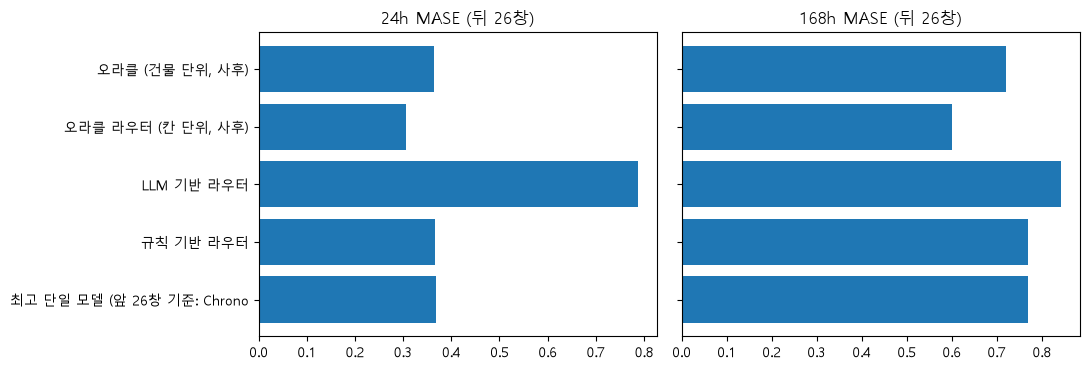

In [11]:
# 규칙 라우터 vs 최고 단일 모델: 건물별 MASE 쌍 비교 (17쌍)
rows = []
for h in H:
    a = per_b[(h, f"최고 단일 모델 (앞 26창 기준: {DEFAULT[h]})")]
    b = per_b[(h, "규칙 기반 라우터")]
    d = a - b
    rows.append({"horizon": h, "단일 MASE": a.mean(), "규칙 라우터 MASE": b.mean(), "개선율(%)": d.mean() / a.mean() * 100,
                 "라우터가 나은 건물": int((d > 1e-12).sum()), "같은 건물": int((d.abs() <= 1e-12).sum()),
                 "Wilcoxon p": wilcoxon(d).pvalue if (d.abs() > 1e-12).any() else np.nan})
pair = pd.DataFrame(rows)
pair.to_csv(OUT / "rule_vs_single_paired.csv", index=False, encoding="utf-8")
print(pair.round(4).to_string(index=False))

# 오라클이 얼마나 앞서는가: 라우팅 여지
gap = []
for h in H:
    s = cmp_df[(cmp_df.horizon == h)].set_index("방식")["MASE"]
    single = s[f"최고 단일 모델 (앞 26창 기준: {DEFAULT[h]})"]
    gap.append({"horizon": h, "단일": single, "오라클(건물)": s["오라클 (건물 단위, 사후)"], "오라클(칸)": s["오라클 라우터 (칸 단위, 사후)"],
                "격차(건물, %)": (single - s["오라클 (건물 단위, 사후)"]) / single * 100, "격차(칸, %)": (single - s["오라클 라우터 (칸 단위, 사후)"]) / single * 100})
gap = pd.DataFrame(gap)
gap.to_csv(OUT / "oracle_gap.csv", index=False, encoding="utf-8")
print()
print(gap.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, h in zip(axes, H):
    d = cmp_df[(cmp_df.horizon == h) & ~cmp_df["방식"].str.startswith("  ") & cmp_df["MASE"].notna()]
    ax.barh(d["방식"].str.slice(0, 26), d["MASE"]); ax.set_title(f"{h}h MASE (뒤 26창)"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(OUT / "router_comparison.png", dpi=110); plt.show()

## 과제 10-6. 실패 분석

- **라우터가 단일 모델보다 나빴던 칸**(regret) 상위 3건. 규칙 라우터가 기본값과 같다면 regret 이 없으므로 아래 '놓친 칸'이 대신 설명 대상이다.
- **놓친 칸**: 오라클은 이겼는데 라우터는 못 고른 칸 — 신호가 승패를 못 가렸다는 증거.

In [12]:
rows = []
for h in H:
    P, lg = pools[h], logs[("rule", h)]
    mm = lg.copy()
    mm["E_router"] = [cm[h][m][w, P.buildings.index(b)] for w, b, m in zip(mm.window, mm.building, mm.model)]
    mm["E_default"] = [cm[h][DEFAULT[h]][w, P.buildings.index(b)] for w, b in zip(mm.window, mm.building)]
    mm["E_best"] = [min(cm[h][n][w, P.buildings.index(b)] for n in rt.POOL) for w, b in zip(mm.window, mm.building)]
    mm["best_model"] = [min(rt.POOL, key=lambda n: cm[h][n][w, P.buildings.index(b)]) for w, b in zip(mm.window, mm.building)]
    mm["regret"] = mm["E_router"] - mm["E_default"]
    mm["missed"] = mm["E_default"] - mm["E_best"]
    mm["horizon"] = h
    rows.append(mm)
cases = pd.concat(rows, ignore_index=True)
cols = ["horizon", "window", "building", "model", "reason", "best_model", "E_router", "E_default", "E_best", "acf168", "recent_naive_mase", "miss_28d"]
worst = cases[cases.regret > 1e-9].sort_values("regret", ascending=False).drop_duplicates(["horizon", "building"]).groupby("horizon").head(3)
missed = cases.sort_values("missed", ascending=False).drop_duplicates(["horizon", "building"]).groupby("horizon").head(3)
print("라우터가 단일 모델보다 나빴던 칸 (regret>0) 상위:", "없음" if worst.empty else "")
if not worst.empty:
    print(worst[cols].round(3).to_string(index=False))
print()
print("오라클은 이기는데 라우터가 못 잡은 칸 상위 (horizon별 3건)")
print(missed[cols].round(3).to_string(index=False))
worst[cols].to_csv(OUT / "failure_regret.csv", index=False, encoding="utf-8")
missed[cols].to_csv(OUT / "failure_missed.csv", index=False, encoding="utf-8")

라우터가 단일 모델보다 나빴던 칸 (regret>0) 상위: 
 horizon  window             building     model                          reason      best_model  E_router  E_default  E_best  acf168  recent_naive_mase  miss_28d
      24      44 Rat_assembly_Pauline Chronos-2 규칙1: recent_naive_mase <= 0.329 Chronos-2 + 공변량     0.233      0.154   0.154   0.397              0.294     0.000
      24      33    Bull_office_Sally Chronos-2 규칙1: recent_naive_mase <= 0.329 Chronos-2 + 공변량     0.149      0.093   0.093  -0.049              0.172     0.000
      24      46     Rat_office_Craig Chronos-2 규칙1: recent_naive_mase <= 0.329 Chronos-2 + 공변량     0.129      0.075   0.075   0.025              0.220     0.004

오라클은 이기는데 라우터가 못 잡은 칸 상위 (horizon별 3건)
 horizon  window            building           model              reason       best_model  E_router  E_default  E_best  acf168  recent_naive_mase  miss_28d
     168      47    Bull_office_Ella Chronos-2 + 공변량 기본값 Chronos-2 + 공변량 LightGBM (local)    20.159     20.159   0.556  -

## 진단 (사후 분석): 오라클 이득이 어디서 나오나

⚠ 평가창을 본 뒤의 분석이라 **규칙을 만드는 데 쓰지 않는다** — 라우터가 오라클을 못 따라가는 이유를 설명하기 위한 것.
이득 = (기본값 모델 칸 MASE − 그 칸의 최선 모델 MASE). 이득이 소수의 칸·건물·시기에 몰려 있는지, 그리고 '최근 잔차 급증' 신호가 앞·뒤 창에서 같은 방향으로 작동하는지 본다.

In [13]:
win = state["window"].to_numpy()
rows, conc = [], []
for h in H:
    E = pd.DataFrame({n: cm[h][n].reshape(-1) for n in rt.POOL})
    g_ev = (E[DEFAULT[h]] - E.min(axis=1))[win >= 26].reset_index(drop=True)
    mon = pd.Series(g_ev.to_numpy().reshape(26, 17).sum(axis=1), index=pools[h].origin_ts[26:].strftime("%m")).groupby(level=0).sum()
    bld = pd.Series(g_ev.to_numpy().reshape(26, 17).sum(axis=0), index=pools[h].buildings).sort_values(ascending=False)
    conc.append({"horizon": h, "상위 10칸 비중": g_ev.sort_values(ascending=False).head(10).sum() / g_ev.sum(), "가장 큰 달": mon.idxmax(),
                 "그 달 비중": mon.max() / mon.sum(), "상위 2개 건물": ", ".join(bld.index[:2]), "상위 2개 건물 비중": bld.head(2).sum() / bld.sum()})
    for thr in (2, 3, 5):
        for tgt in ["LightGBM (local)", "Seasonal Naive"]:
            for part, mask in [("앞 26창", win < 26), ("뒤 26창", win >= 26)]:
                m = mask & (state["recent_naive_mase"].to_numpy() > thr)
                r = rt.check_rule(None, E[mask].reset_index(drop=True), m[mask], tgt, DEFAULT[h])
                rows.append({"horizon": h, "조건": f"recent_naive_mase > {thr}", "대상": tgt, "구간": part, "발동 칸": r["발동 칸 수"], "개선율(%)": r["개선율(%)"]})
conc = pd.DataFrame(conc)
conc.to_csv(OUT / "oracle_gain_concentration.csv", index=False, encoding="utf-8")
print(conc.round(3).to_string(index=False))
surge = pd.DataFrame(rows).pivot_table(index=["horizon", "조건", "대상"], columns="구간", values=["발동 칸", "개선율(%)"])
surge.to_csv(OUT / "posthoc_surge_rule.csv", encoding="utf-8")
print()
print(surge.round(1).to_string())

 horizon  상위 10칸 비중 가장 큰 달  그 달 비중                            상위 2개 건물  상위 2개 건물 비중
      24      0.397     12   0.195   Rat_office_Lora, Fox_office_Vicki        0.296
     168      0.688     11   0.592 Bull_office_Ella, Bull_office_Sally        0.525

                                                개선율(%)         발동 칸      
구간                                               뒤 26창  앞 26창 뒤 26창 앞 26창
horizon 조건                    대상                                         
24      recent_naive_mase > 2 LightGBM (local)   -98.3  -95.2  45.0  39.0
                              Seasonal Naive    -517.7 -304.4  45.0  39.0
        recent_naive_mase > 3 LightGBM (local)  -207.2 -102.3  21.0  14.0
                              Seasonal Naive   -1213.4 -547.1  21.0  14.0
        recent_naive_mase > 5 LightGBM (local)   -53.9  -99.1   6.0   3.0
                              Seasonal Naive   -6560.5 -842.3   6.0   3.0
168     recent_naive_mase > 2 LightGBM (local)    14.3  -32.7  45.0  39.0
       

## 보조: 콜드스타트(이력 2주)에서의 라우팅 여지

본 비교(이력 1년 이상)는 모든 건물에서 한 모델이 거의 이긴다. 6주차 콜드스타트 시나리오(직전 2주만 보유)는 모델 순위가 크게 흔들려 라우팅 여지가 다를 수 있다. 윈도우별 예측이 저장돼 있지 않아 **건물 단위 MASE로만** 단일 최고 대 오라클 격차를 본다.

In [14]:
import re
def cache(tag, h):
    p = ROOT / "results/wk6/mase_cache" / f"{re.sub(r'[^0-9A-Za-z가-힣]+', '_', tag)}_{h}h.csv"
    return pd.read_csv(p, index_col=0)["MASE"]

rows = []
full_pb = pd.read_csv(ROOT / "results/wk6/per_building_mase.csv", index_col=0)
for h in H:
    for cond, get in [("이력 1년 이상 (52창 전체)", lambda n: full_pb[f"{n}|{h}h"]), ("콜드스타트 (직전 2주)", lambda n: cache("coldstart " + n, h))]:
        M = pd.DataFrame({n: get(n) for n in rt.POOL})
        best = M.mean().idxmin()
        rows.append({"horizon": h, "조건": cond, "최고 단일": best, "단일 MASE": M.mean().min(), "오라클(건물) MASE": M.min(axis=1).mean(),
                     "격차(%)": (M.mean().min() - M.min(axis=1).mean()) / M.mean().min() * 100,
                     "건물별 승자": M.idxmin(axis=1).value_counts().to_dict()})
cold = pd.DataFrame(rows)
cold.to_csv(OUT / "coldstart_oracle_gap.csv", index=False, encoding="utf-8")
print(cold.round(4).to_string(index=False))

 horizon                조건           최고 단일  단일 MASE  오라클(건물) MASE  격차(%)                                                                               건물별 승자
      24 이력 1년 이상 (52창 전체) Chronos-2 + 공변량   0.3545        0.3517 0.7947                                              {'Chronos-2 + 공변량': 13, 'Chronos-2': 4}
      24     콜드스타트 (직전 2주) Chronos-2 + 공변량   0.3917        0.3843 1.9014                                              {'Chronos-2 + 공변량': 11, 'Chronos-2': 6}
     168 이력 1년 이상 (52창 전체) Chronos-2 + 공변량   0.6969        0.6860 1.5570                         {'Chronos-2 + 공변량': 12, 'Chronos-2': 4, 'Seasonal Naive': 1}
     168     콜드스타트 (직전 2주) Chronos-2 + 공변량   0.7760        0.7504 3.2947 {'Chronos-2 + 공변량': 13, 'Chronos-2': 2, 'Seasonal Naive': 1, 'LightGBM (global)': 1}


In [15]:
# 12주차 누적표용 한 줄
cum = cmp_df[cmp_df["방식"].isin(["규칙 기반 라우터", "LLM 기반 라우터"])].pivot(index="방식", columns="horizon", values="MASE")
cum.columns = [f"MASE {h}h (뒤 26창)" for h in cum.columns]
cum.to_csv(OUT / "cumulative_row.csv", encoding="utf-8")
json.dump({"python": platform.python_version(), "pool": rt.POOL, "fit_windows": [int(rt.FIT_W[0]), int(rt.FIT_W[-1])],
           "eval_windows": [int(rt.EVAL_W[0]), int(rt.EVAL_W[-1])], "default": DEFAULT, "llm_model": OPENAI_MODEL if KEY else None,
           "llm_full_run": bool(KEY and RUN_FULL_LLM)}, open(OUT / "env.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print(cum.round(4).to_string())

            MASE 24h (뒤 26창)  MASE 168h (뒤 26창)
방식                                             
LLM 기반 라우터            0.7875             0.8427
규칙 기반 라우터             0.3669             0.7689
